# C04 · Tỷ trọng đối tác thương mại

**Câu hỏi Q2.** Mức độ tập trung đối tác của Việt Nam thay đổi thế nào theo thời gian?

**Lâm Thanh Nghi** · Mở notebook trong dự án đã giải nén có cài các thư viện từ `requirements.txt` và chọn **Run All** để tạo hai hình.

Dùng quy tắc mã đối tác của bộ định dạng dự án. Loại nhóm BACI `490 / S19` (*Các nền kinh tế châu Á khác, chưa phân loại*) và mã tổng hợp khỏi cả bảng xếp hạng lẫn mẫu số. Tính tỷ trọng theo từng năm và từng chiều thương mại.

## C04A · Thay đổi tỷ trọng đối tác xuất khẩu

- **Task** · (Q2.2) So sánh tỷ trọng đối tác xuất khẩu năm 2005 và 2024.
- **Dạng** · Biểu đồ hai điểm nối ngang. Mỗi hàng là một đối tác.
- **Lý do** · Đo hướng và độ lớn thay đổi bằng điểm phần trăm.
- **Xử lý** · Chọn sáu đối tác theo tổng kim ngạch xuất khẩu ở hai mốc. Chia cho tổng xuất khẩu của toàn bộ đối tác hợp lệ cùng năm. Giữ cùng sáu đối tác tại hai mốc. Nếu một đối tác vắng mặt trong bảng của một năm, dùng 0 tại năm đó.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import rc_context
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong thư mục dự án đã giải nén.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    SOURCE, SUBTITLE, TRADE_FLOW_COLORS, TRADE_FLOW_LABELS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, TRADE_FLOW_ORDER,
    apply_style, format_number, format_percent, format_percentage_points,
    is_partner_code,
)

DATA_DIR = ROOT / "data" / "clean"
YEARS = tuple(range(2005, 2025))

def tai_du_lieu(data_dir=DATA_DIR):
    raw = pd.read_csv(data_dir / "partner_year.csv",
                      dtype={"partner_code": str, "partner_iso3": str})
    valid = raw.partner_iso3.fillna("").map(is_partner_code)
    valid &= ~raw.partner_code.str.lstrip("0").isin(["", "999"])
    data = raw.loc[valid & raw.year.between(2005, 2024)
                   & raw.trade_flow.isin(TRADE_FLOW_ORDER)].copy()
    assert np.isfinite(data.trade_usd).all() and data.trade_usd.ge(0).all()
    keys = ["year", "trade_flow", "partner_code"]
    data = data.groupby(keys, as_index=False).agg(
        trade_usd=("trade_usd", "sum"), partner_iso3=("partner_iso3", "first"))
    totals = data.groupby(["year", "trade_flow"]).trade_usd.transform("sum")
    assert totals.gt(0).all()
    data["share"] = data.trade_usd / totals
    summed = data.groupby(["year", "trade_flow"]).share.sum()
    assert len(summed) == 40 and np.allclose(summed, 1, atol=1e-12, rtol=0)
    return data

partners = tai_du_lieu()

In [2]:
NAMES = {"USA": "Hoa Kỳ", "CHN": "Trung Quốc", "JPN": "Nhật Bản", "KOR": "Hàn Quốc",
         "HKG": "Hồng Kông (Trung Quốc)", "DEU": "Đức", "SGP": "Singapore", "THA": "Thái Lan"}

def xu_ly_c04(data, flow):
    rows = data.loc[data.year.isin([2005, 2024]) & data.trade_flow.eq(flow)]
    totals = rows.groupby("partner_code").trade_usd.sum()
    top = totals.sort_index().nlargest(6).index
    chosen = rows.loc[rows.partner_code.isin(top)]
    wide = chosen.pivot(index="partner_code", columns="year", values="share")
    wide = wide.reindex(index=top, columns=[2005, 2024]).fillna(0)
    iso = chosen.sort_values("year").drop_duplicates("partner_code", keep="last")
    iso = iso.set_index("partner_code").partner_iso3.reindex(top)
    wide.index = iso.map(NAMES).fillna(iso)
    wide.index.name = "Đối tác"
    wide["Thay đổi"] = 100 * (wide[2024] - wide[2005])
    return wide

def plot_c04(data, title, flow):
    with apply_style():
        fig = Figure(figsize=(10.5, 5.5))
        ax = fig.subplots()
        fig.subplots_adjust(left=.26, right=.95, top=.72, bottom=.18)
        trang_tri(fig, title, "Việt Nam · 2005 và 2024")
        y = np.arange(len(data))
        ax.hlines(y, data[[2005, 2024]].min(axis=1), data[[2005, 2024]].max(axis=1),
                  color="#8D959B", linewidth=1.5)
        for year, marker, fill, dy in [(2005, "o", "white", 7), (2024, "s", TRADE_FLOW_COLORS[flow], -7)]:
            values = data[year]
            ax.scatter(values, y, marker=marker, edgecolors=TRADE_FLOW_COLORS[flow],
                       facecolors=fill, label=str(year), zorder=3)
            for yi, value in zip(y, values):
                ax.annotate(format_percent(value), (value, yi), xytext=(0, dy),
                            textcoords="offset points", ha="center",
                            va="bottom" if year == 2005 else "top", fontsize=9)
        ax.set(yticks=y, yticklabels=data.index, ylim=(len(data) - .5, -.5),
               xlim=(0, .5), xticks=np.arange(6)/10, xlabel="Tỷ trọng (%)")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: format_percent(v, 0)))
        ax.grid(axis="x", alpha=.25)
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="center", bbox_to_anchor=(.5, .79),
                   ncol=2)
    return fig

def trang_tri(fig, title, scope):
    fig.suptitle(title, y=.96)
    fig.text(.5, .86, scope, **SUBTITLE)
    fig.text(.5, .035, "Nguồn dữ liệu: CEPII BACI HS2002 V202601 · partner_year.csv", **SOURCE)

def luu_hinh(fig, name):
    folder = ROOT / "outputs" / "core_charts" / name[:3]
    folder.mkdir(parents=True, exist_ok=True)
    paths = tuple(folder / f"{name}.{ext}" for ext in ("png", "svg"))
    with apply_style(), rc_context({"svg.fonttype": "path"}):
        for path in paths:
            fig.savefig(path)
    display(Image(filename=str(paths[0]), width=900))

                         2005   2024 Thay đổi (điểm %)
Đối tác                                               
Hoa Kỳ                  19.6%  28.2%              +8.6
Trung Quốc               7.6%  18.9%             +11.3
Nhật Bản                13.0%   5.3%              −7.7
Hàn Quốc                 2.2%   5.7%              +3.5
Hồng Kông (Trung Quốc)   1.6%   4.2%              +2.7
Đức                      4.8%   3.1%              −1.7


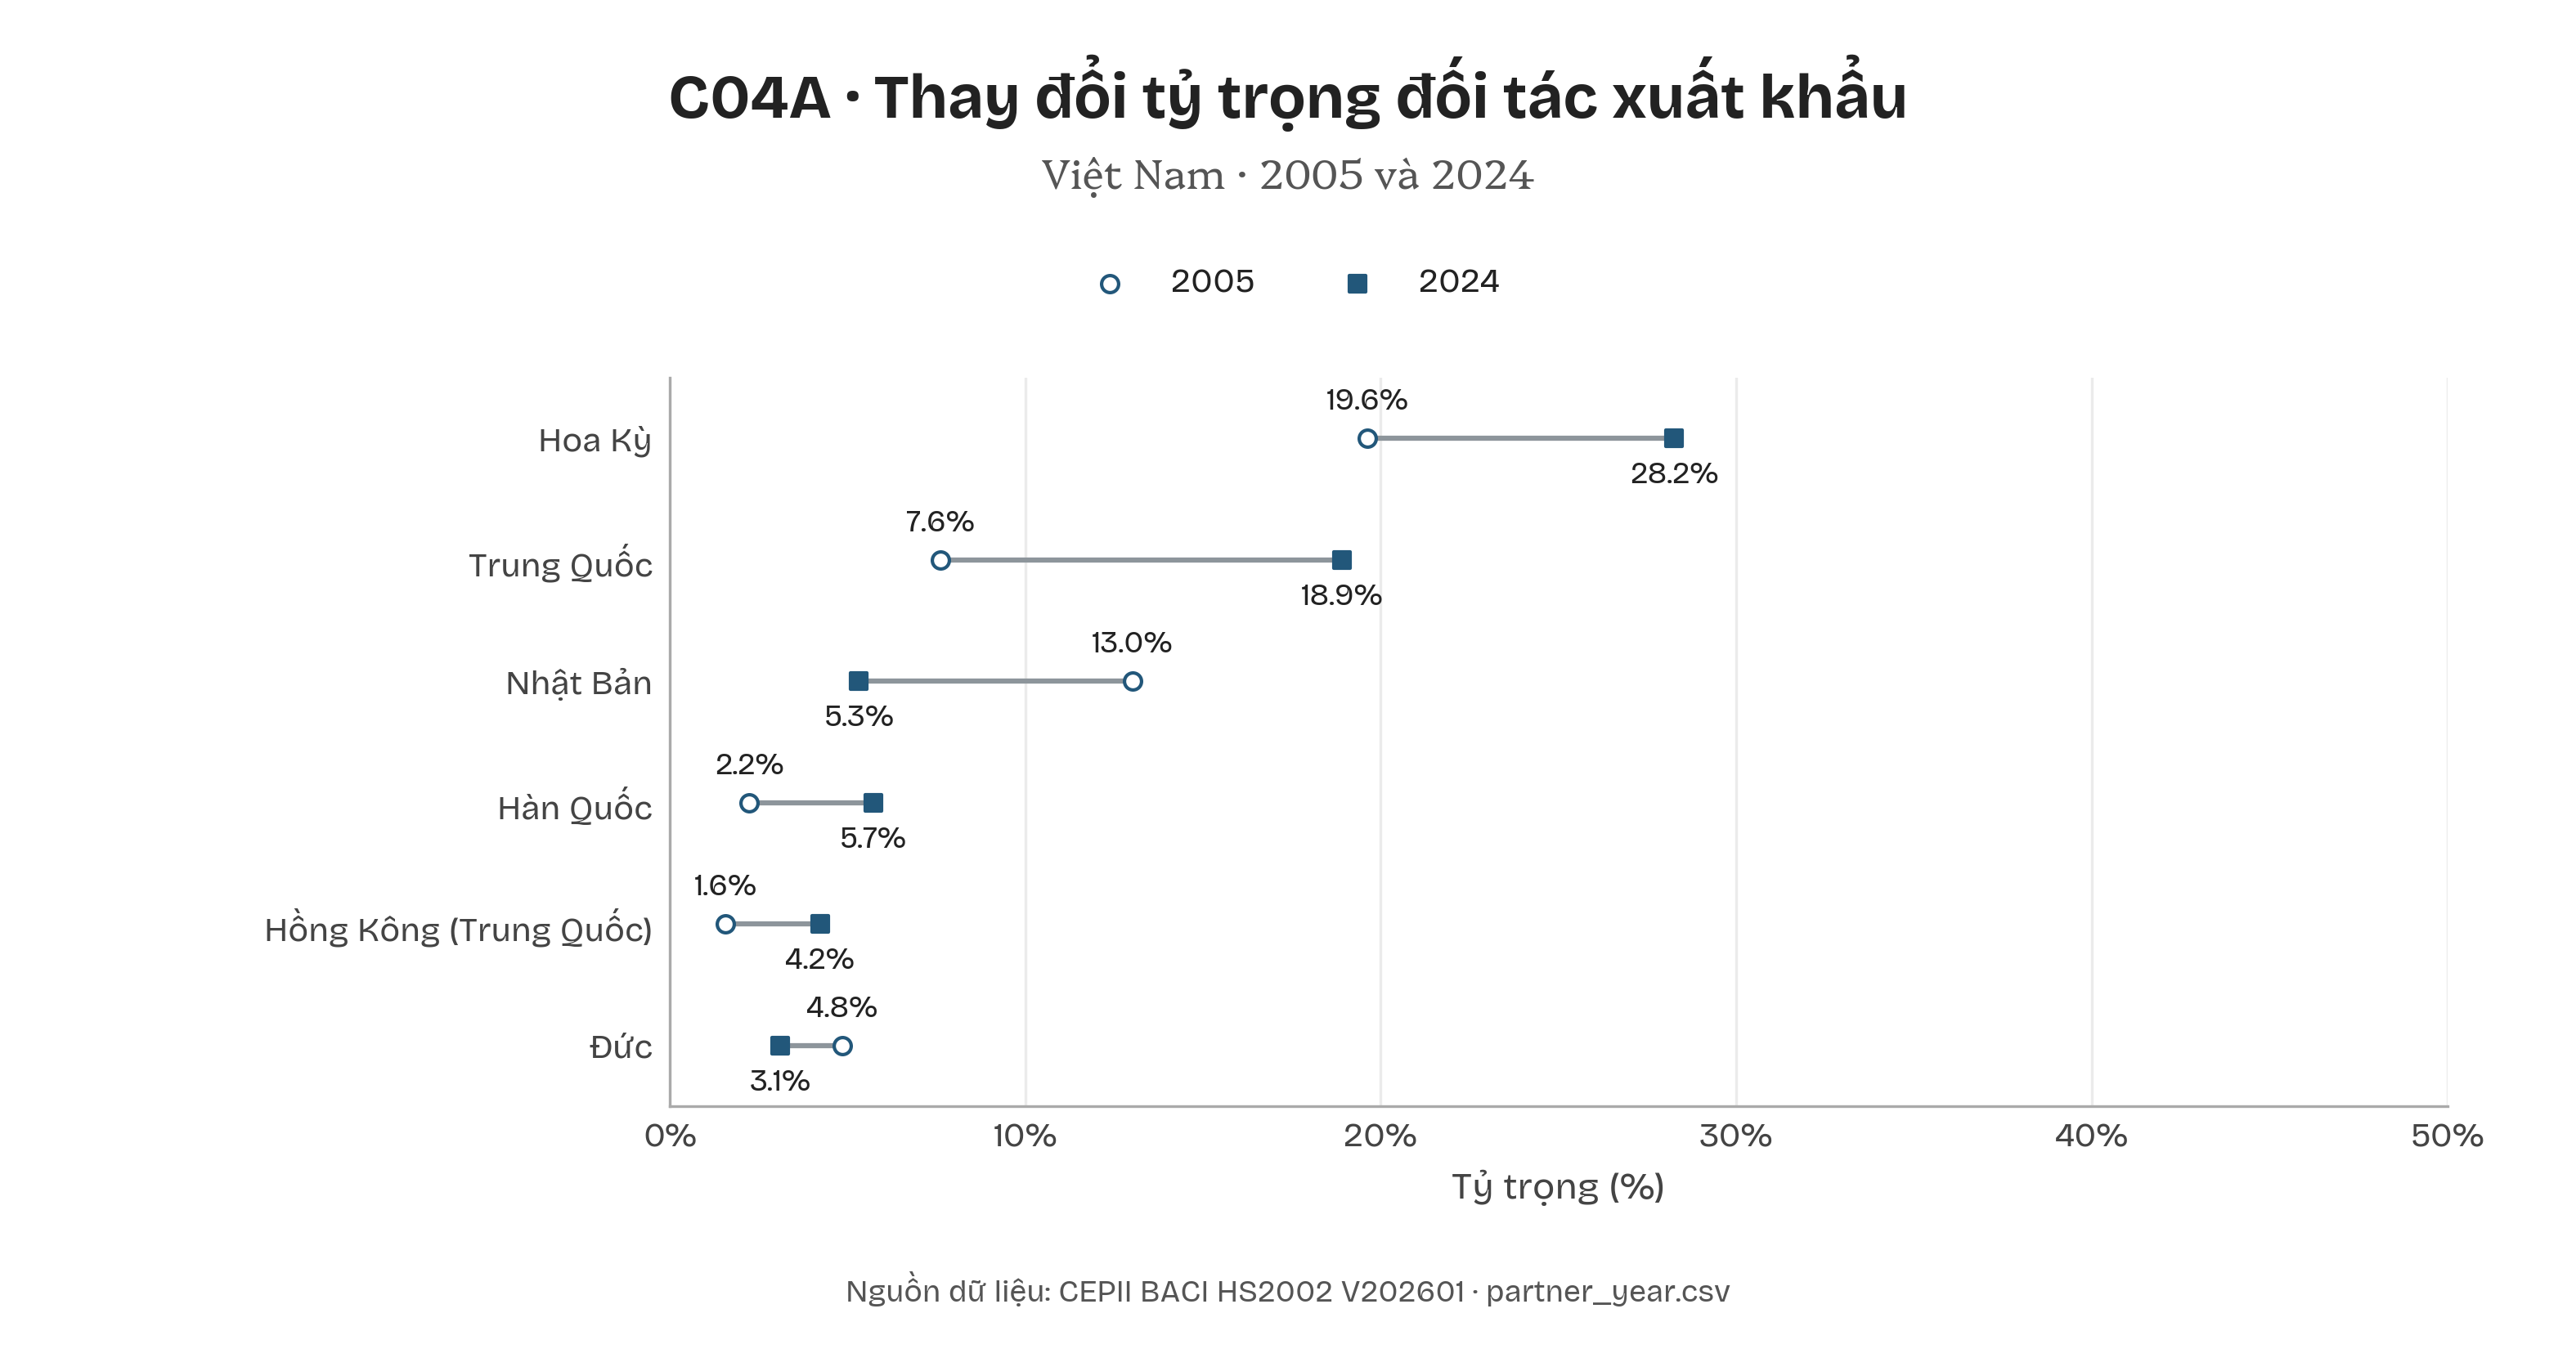

In [3]:
MA_BIEU_DO = "C04A"
data = xu_ly_c04(partners, "Export")
fig = plot_c04(data, "C04A · Thay đổi tỷ trọng đối tác xuất khẩu", "Export")
assert len(data) == 6
assert np.allclose(data["Thay đổi"], 100 * (data[2024] - data[2005]))
for points, year in zip(fig.axes[0].collections[1:], (2005, 2024), strict=True):
    assert np.allclose(points.get_offsets()[:, 0], data[year])
table = data.copy()
for year in (2005, 2024):
    table[year] = table[year].map(format_percent)
table["Thay đổi"] = table["Thay đổi"].map(lambda v: format_number(v, 1, signed=True))
print(table.rename(columns={"Thay đổi": "Thay đổi (điểm %)"}).rename_axis(columns=None))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C04A

Trong sáu đối tác, tỷ trọng xuất khẩu của **Trung Quốc** thay đổi mạnh nhất, tăng **11.3 điểm phần trăm**, từ **7.6%** lên **18.9%**.

## C04B · Thay đổi tỷ trọng đối tác nhập khẩu

- **Task** · (Q2.2) So sánh tỷ trọng đối tác nhập khẩu năm 2005 và 2024.
- **Dạng** · Biểu đồ hai điểm nối ngang. Mỗi hàng là một đối tác.
- **Lý do** · Đo hướng và độ lớn thay đổi bằng điểm phần trăm.
- **Xử lý** · Chọn sáu đối tác theo tổng kim ngạch nhập khẩu ở hai mốc. Chia cho tổng nhập khẩu của toàn bộ đối tác hợp lệ cùng năm. Giữ cùng sáu đối tác tại hai mốc. Nếu một đối tác vắng mặt trong bảng của một năm, dùng 0 tại năm đó.

**Nguồn** · `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601.

                         2005   2024 Thay đổi (điểm %)
Đối tác                                               
Trung Quốc              17.1%  43.8%             +26.7
Hàn Quốc                11.4%  16.1%              +4.7
Singapore               12.7%   4.7%              −8.0
Hồng Kông (Trung Quốc)   4.1%   5.4%              +1.4
Nhật Bản                12.3%   4.4%              −7.9
Thái Lan                 8.1%   3.2%              −4.9


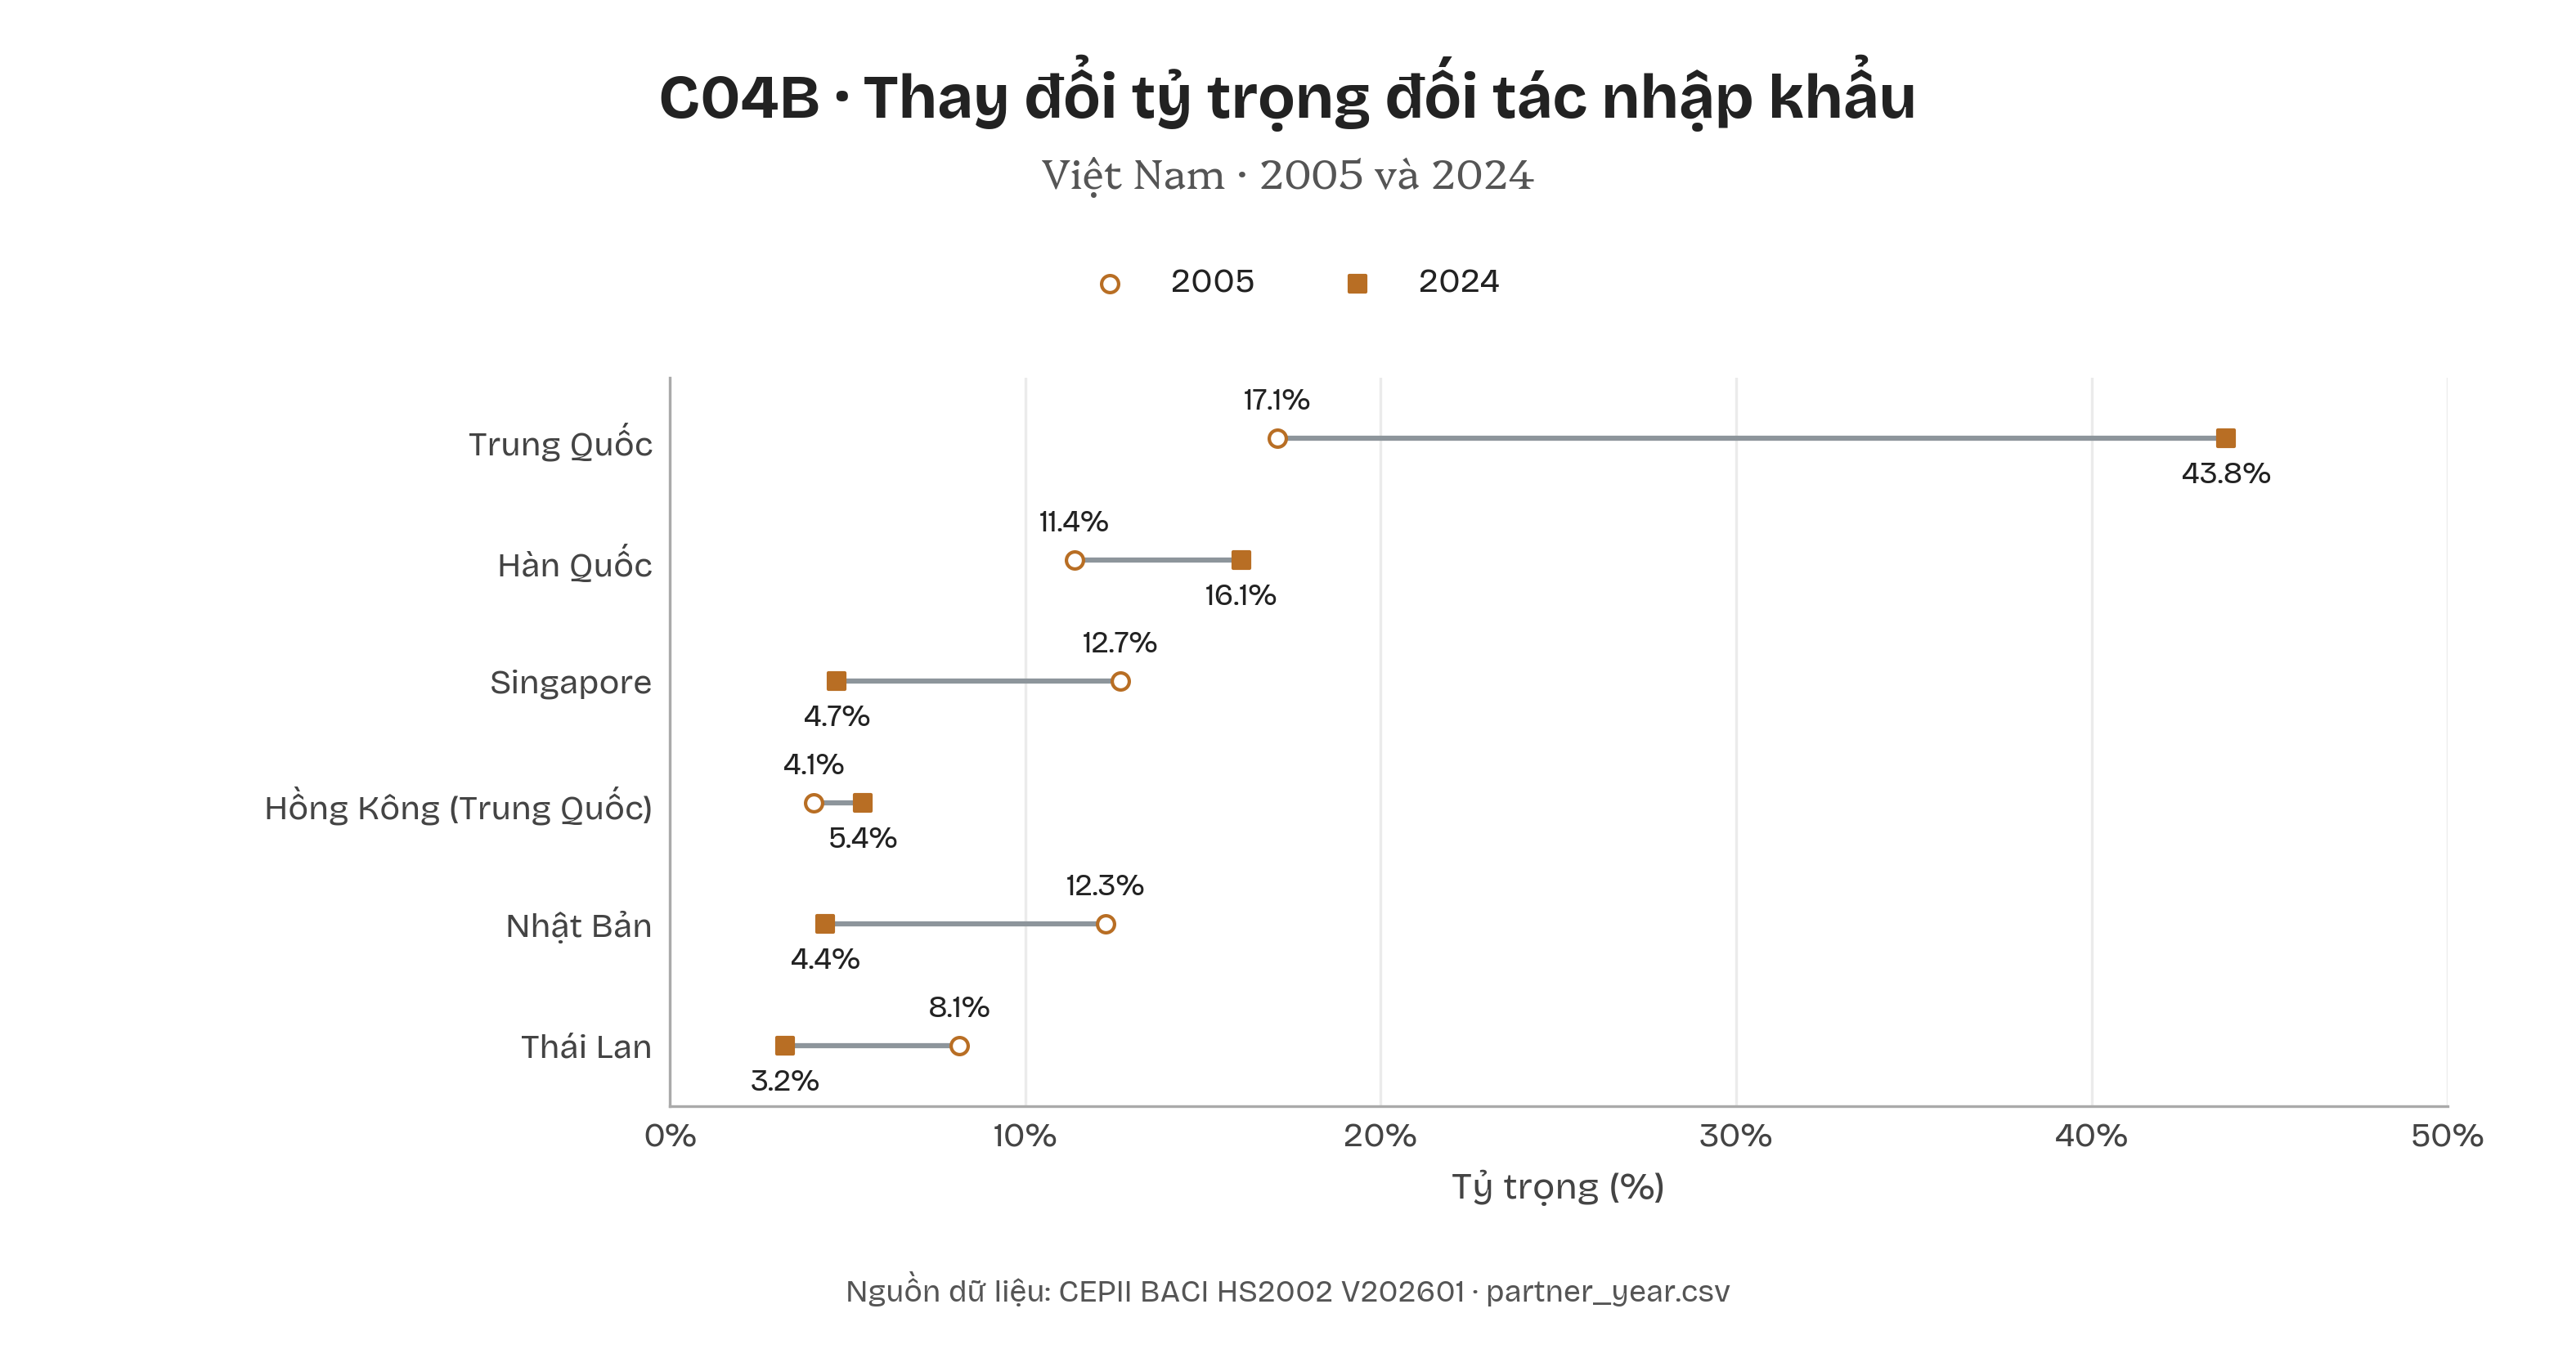

In [4]:
MA_BIEU_DO = "C04B"
data = xu_ly_c04(partners, "Import")
fig = plot_c04(data, "C04B · Thay đổi tỷ trọng đối tác nhập khẩu", "Import")
assert len(data) == 6
assert np.allclose(data["Thay đổi"], 100 * (data[2024] - data[2005]))
for points, year in zip(fig.axes[0].collections[1:], (2005, 2024), strict=True):
    assert np.allclose(points.get_offsets()[:, 0], data[year])
table = data.copy()
for year in (2005, 2024):
    table[year] = table[year].map(format_percent)
table["Thay đổi"] = table["Thay đổi"].map(lambda v: format_number(v, 1, signed=True))
print(table.rename(columns={"Thay đổi": "Thay đổi (điểm %)"}).rename_axis(columns=None))
luu_hinh(fig, MA_BIEU_DO)

### Kết luận C04B

Trong sáu đối tác, tỷ trọng nhập khẩu của **Trung Quốc** thay đổi mạnh nhất, tăng **26.7 điểm phần trăm**, từ **17.1%** lên **43.8%**.